In [138]:
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from matplotlib import colors as mcolors
import numpy as np

In [140]:
data = pd.read_csv('sells_marketplace_data.csv')
data.head(3)

,order_id,customer_id,order_date,sku,category,price,quantity,discount_amount,payment_method,delivery_type,region,is_returned,return_reason,rating
0,ORD-Y2025-001-8297,CUST-2925,2025-01-01 19:27:00,SKU-1264,Электроника,17331,3,12422,card,Courier,Самара,0,NaN,5
1,ORD-Y2025-001-8137,CUST-1804,2025-01-01 15:09:00,SKU-1770,Одежда,2067,1,551,installment,Courier,Екатеринбург,0,NaN,4
2,ORD-Y2025-001-7098,CUST-0532,2025-01-01 19:54:00,SKU-1493,Электроника,100,1,0,installment,Pvz,Ростов-на-Дону,0,NaN,4


Посчитаем выручку и посмотрим график продаж по месяцам.

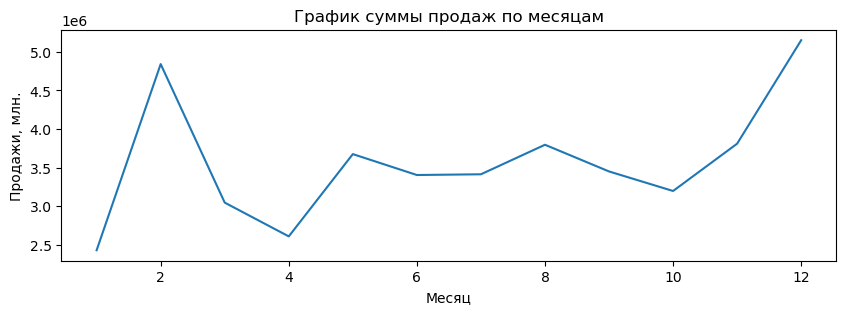

In [143]:
data['order_date'] = pd.to_datetime(data['order_date'])
data['revenue'] = (data['price'] * data['quantity'] - data['discount_amount'])

month_rev = data.groupby(data['order_date'].dt.month).agg(revenue = ('revenue', 'sum')).reset_index()

plt.figure(figsize=(10, 3))
plt.plot(month_rev['order_date'], month_rev['revenue'])
plt.xlabel('Месяц')
plt.ylabel('Продажи, млн.')
plt.title('График суммы продаж по месяцам')
plt.show()

Похоже на правду, пики на графике совпадают с праздниками и сезонными событиями.   
Проведем RFM-анализ покупателей, чтобы выявить таких, кого стоит привлекать, а на кого лучше не тратить ресурсы.  
Для начала рассчитаем каждую величину и посмотрим как они распределены.

In [185]:
rfm = data.groupby('customer_id').agg(
    recency=('order_date', lambda x: (data['order_date'].max() - x.max()).days),
    frequency=('order_id', 'count'),
    monetary=('revenue', 'sum')
).reset_index()
rfm.head(5)

,customer_id,recency,frequency,monetary
0,CUST-0001,55,12,44894
1,CUST-0002,152,8,31698
2,CUST-0003,5,7,33638
3,CUST-0004,315,1,13438
4,CUST-0005,228,1,21770


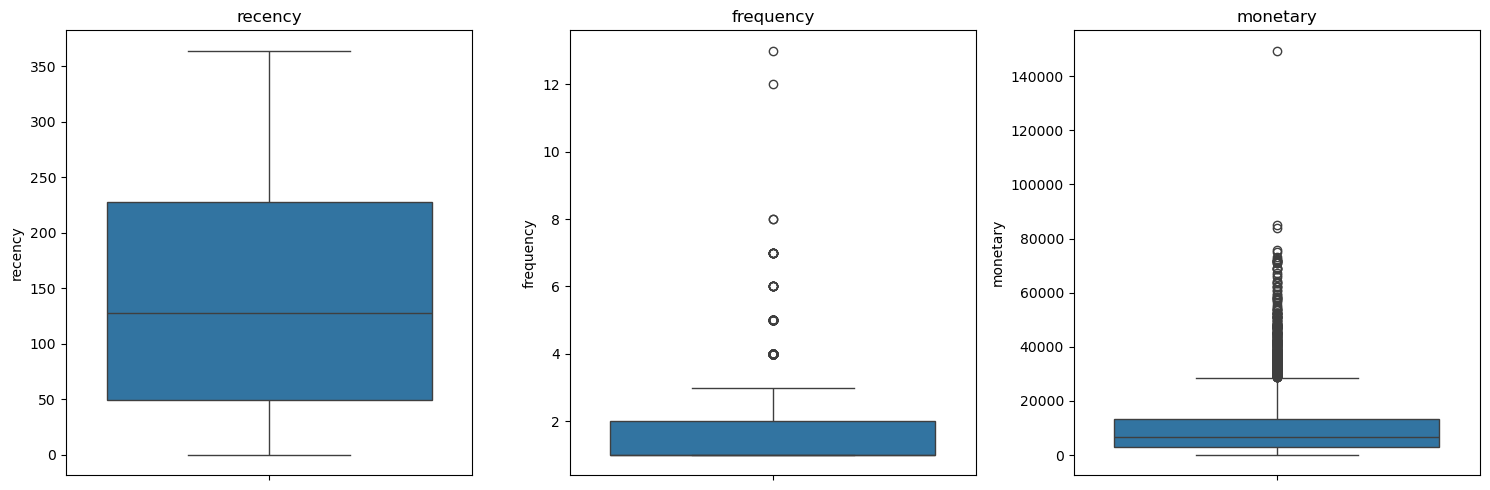

In [148]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5))

for j, col in enumerate(rfm.drop('customer_id', axis=1).columns):
    sns.boxplot(data=rfm, y=col, ax=axs[j])
    axs[j].set_title(col)

plt.tight_layout()
plt.show()

In [150]:
df = data.sort_values(['customer_id', 'order_date'])
df['days_since_last_order'] = (
    df.groupby('customer_id')['order_date']
      .diff()
      .dt.days
)
avg_days_between = df['days_since_last_order'].median()
print('Среднее количество дней между заказами (по всем интервалам):', avg_days_between)
client_avg = (
    df.groupby('customer_id')['days_since_last_order']
      .median() 
      .dropna()
)
avg_by_client = client_avg.mean()
print('Среднее по клиентам (mean of means):', avg_by_client)

Среднее количество дней между заказами (по всем интервалам): 76.0
Среднее по клиентам (mean of means): 107.99243421052631


Возьмем примерные границы для метрик, глядя на распределение.   
В среднем люди делают заказ не чаще 1 раза в 3 месяца, поэтому возьмем 90 дней для верхней границы recency, а 180 дней - для нижней.   
Большинство покупателей сделали только один заказ, это и будет нижней границей для frequency, для верхней - 2 заказа.   
В среднем покупатель потратил около 5000 рублей на заказы за год, это будет нижней границей для monetary, для верхней возьмем примерную границу выбросов.

In [187]:
rfm.loc[rfm['recency'] <= 90, 'recency'] = 3
rfm.loc[(rfm['recency'] > 90) & (rfm['recency'] <= 180), 'recency'] = 2
rfm.loc[rfm['recency'] > 180, 'recency'] = 1

rfm.loc[rfm['frequency'] == 1, 'frequency'] = 1
rfm.loc[rfm['frequency'] == 2, 'frequency'] = 2
rfm.loc[rfm['frequency'] > 2, 'frequency'] = 3

rfm.loc[rfm['monetary'] < 5000, 'monetary'] = 1
rfm.loc[(rfm['monetary'] >= 5000) & (rfm['monetary'] < 30000), 'monetary'] = 2
rfm.loc[rfm['monetary'] >= 30000, 'monetary'] = 3

После перевода метрик в другую шкалу присвоим покупателям такие типы по этим значениям.   
333 - 'VIP' - часто заказываеют, большая годовая сумма   
33(1-2) - 'Постоянные' - часто заказывают, годовая сумма поменьше   
32- - 'Потенциальные постоянные' - недавно сделали 2-й заказ   
31- - 'Новые' - недавно сделали 1-й заказ   
2(1-2)- - 'Засыпающие' - 3-6 месяца назад сделали 1 или 2 заказа   
(1-2)3- - 'Засыпающие постоянные' - больше 3 месяцев назад часто делали заказы   
1(1-2)- - 'Спящие' - больше 6 месяцев назад сделали 1 или 2 заказа   

In [193]:
rfm['type'] = rfm['recency'].astype(str) + rfm['frequency'].astype(str) + rfm['monetary'].astype(str)

rfm.loc[rfm['type'] == '333', 'type'] = 'VIP'
rfm.loc[(rfm['type'].str[:2] == '33')
        & (rfm['type'].str[-1] != '3'), 'type'] = 'Постоянные'

rfm.loc[(rfm['type'].str[:2] == '32'), 'type'] = 'Потенциальные постоянные'
rfm.loc[(rfm['type'].str[:2] == '31'), 'type'] = 'Новые'

rfm.loc[(rfm['type'].str[0] == '2')
        & (rfm['type'].str[1] != '3'), 'type'] = 'Засыпающие'

rfm.loc[(rfm['type'].str[0] != '3')
        & (rfm['type'].str[1] == '3'), 'type'] = 'Засыпающие постоянные'

rfm.loc[(rfm['type'].str[0] == '1')
        & (rfm['type'].str[1] != '3'), 'type'] = 'Спящие'

data = data.merge(rfm[['customer_id', 'type']], on='customer_id', how='left')

Посчитаем по каждому типу сумму выручки и количество покупателей в группе.

In [196]:
cust_typ = (data.groupby('type')
            .agg(revenue=('revenue', 'sum'),
                counts=('customer_id', 'count'))
                 .reset_index())
cust_typ['revenue'] = round((cust_typ['revenue'] / cust_typ['revenue'].sum()) * 100)
cust_typ['counts'] = round((cust_typ['counts'] / cust_typ['counts'].sum()) * 100)
cust_typ = cust_typ.reindex([0,4,5,3,2,1,6])
cust_typ

,type,revenue,counts
0,VIP,10.0,6.0
4,Постоянные,10.0,15.0
5,Потенциальные постоянные,16.0,15.0
3,Новые,10.0,11.0
2,Засыпающие постоянные,10.0,10.0
1,Засыпающие,18.0,18.0
6,Спящие,26.0,25.0


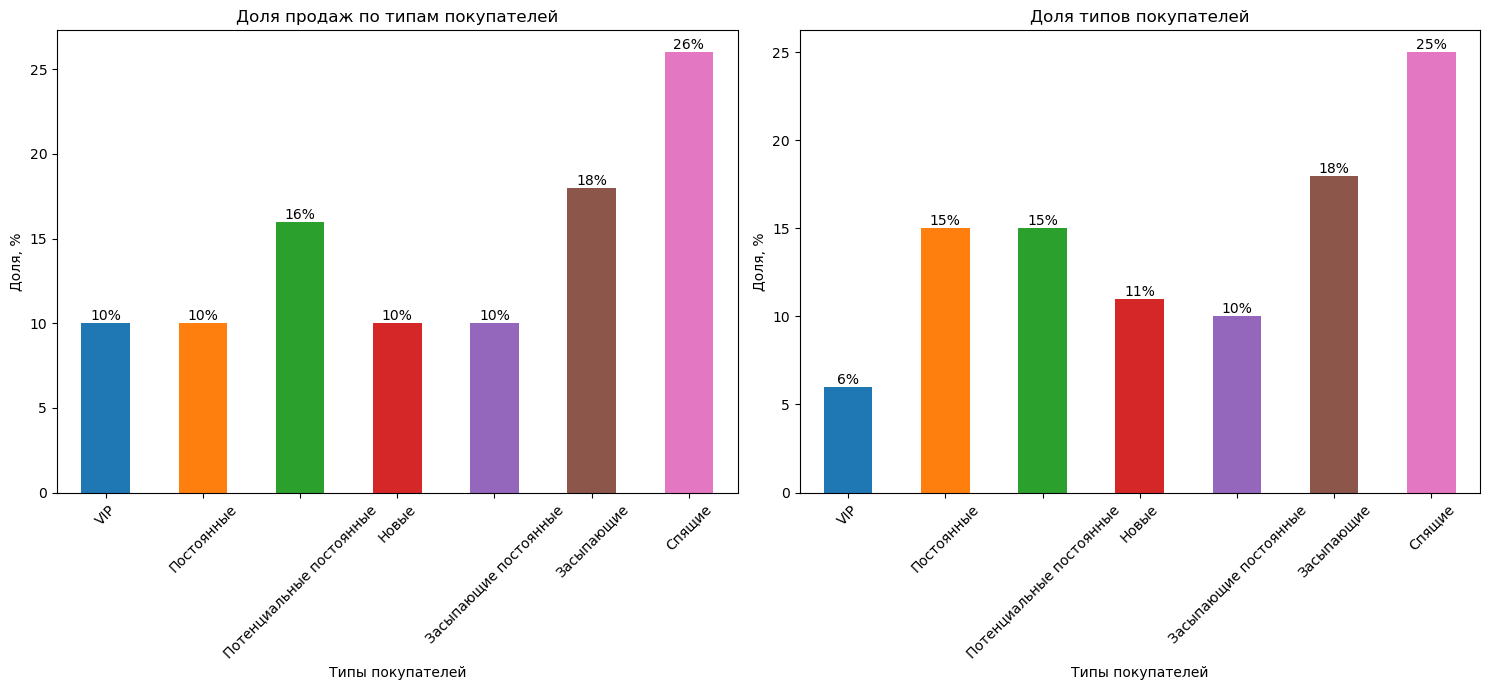

In [161]:
fig, axs = plt.subplots(1, 2, figsize=(15, 7))

ax_left = cust_typ.plot.bar(x='type', y='revenue', legend=False, rot=45, ax=axs[0], color=plt.cm.tab10(np.arange(len(cust_typ))))
ax_left.set_title('Доля продаж по типам покупателей')
ax_left.set_ylabel('Доля, %')
ax_left.set_xlabel('Типы покупателей')


for container in ax_left.containers:
    ax_left.bar_label(container, fmt='%d%%')

ax_right = cust_typ.plot.bar(x='type', y='counts', legend=False, rot=45, ax=axs[1], color=plt.cm.tab10(np.arange(len(cust_typ))))
ax_right.set_title('Доля типов покупателей')
ax_right.set_ylabel('Доля, %')
ax_right.set_xlabel('Типы покупателей')

for container in ax_right.containers:
    ax_right.bar_label(container, fmt='%d%%')

plt.tight_layout()
plt.show()

Таким образом можно выявить неактивных покупателей, которые могут положительно отреагировать на специальную скидку или акцию.   
Далее проанализируем категории товаров.   
Посчитаем по каждой категории сумму выручки и количество заказов.

In [164]:
pro_cat = (data.groupby('category')
            .agg(revenue=('revenue', 'sum'),
                counts=('order_id', 'count'))
                 .reset_index())
pro_cat['revenue'] = round((pro_cat['revenue'] / pro_cat['revenue'].sum()) * 100)
pro_cat['counts'] = round((pro_cat['counts'] / pro_cat['counts'].sum()) * 100)

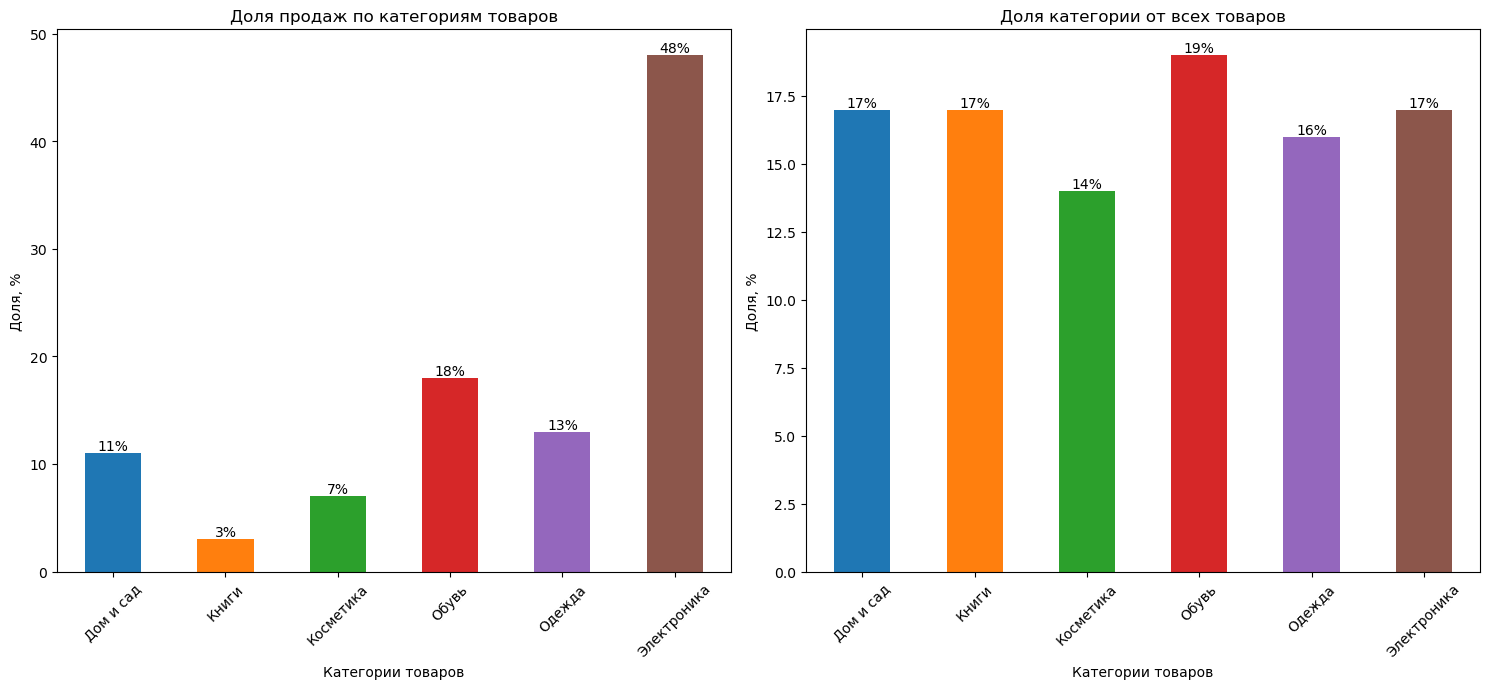

In [166]:
fig, axs = plt.subplots(1, 2, figsize=(15, 7))

ax_left = pro_cat.plot.bar(x='category', y='revenue', legend=False, rot=45, ax=axs[0], color=plt.cm.tab10(np.arange(len(pro_cat))))
ax_left.set_title('Доля продаж по категориям товаров')
ax_left.set_ylabel('Доля, %')
ax_left.set_xlabel('Категории товаров')


for container in ax_left.containers:
    ax_left.bar_label(container, fmt='%d%%')

ax_right = pro_cat.plot.bar(x='category', y='counts', legend=False, rot=45, ax=axs[1], color=plt.cm.tab10(np.arange(len(pro_cat))))
ax_right.set_title('Доля категории от всех товаров')
ax_right.set_ylabel('Доля, %')
ax_right.set_xlabel('Категории товаров')

for container in ax_right.containers:
    ax_right.bar_label(container, fmt='%d%%')

plt.tight_layout()
plt.show()

Почти половина от всей выручки приходится на электронику, хотя количество заказов примерно одинаковое.   
Стоит в первую очередь уделять внимание этой категории.    
Посмотрим в какой категории больше возвратов. 

In [169]:
ret_cat = (data.groupby('category')
            .agg(ret_mean=('is_returned', 'mean'),
                ret_sum=('is_returned', 'sum'))
                 .reset_index())
ret_cat['ret_mean'] = round((ret_cat['ret_mean'] * 100))
ret_cat['ret_sum'] = round((ret_cat['ret_sum'] / ret_cat['ret_sum'].sum()) * 100)

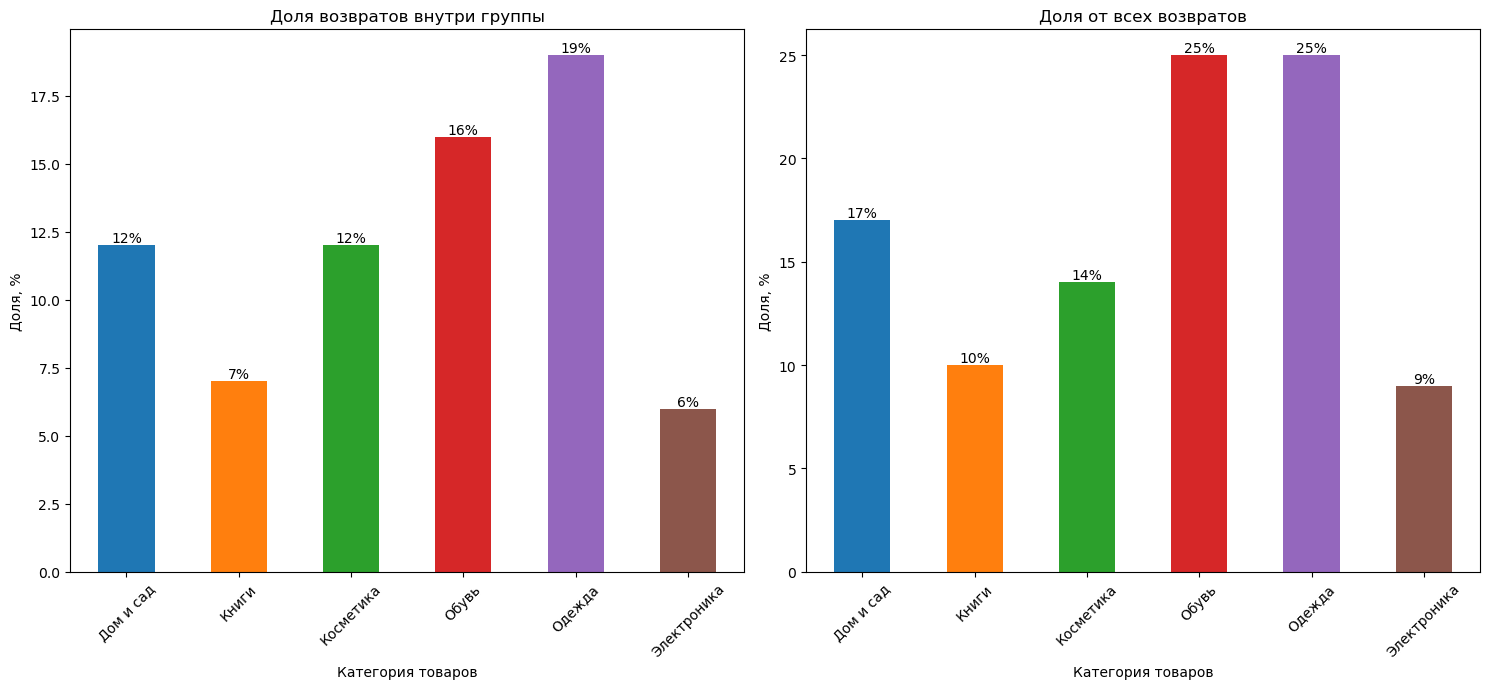

In [171]:
fig, axs = plt.subplots(1, 2, figsize=(15, 7))

ax_left = ret_cat.plot.bar(x='category', y='ret_mean', legend=False, color=plt.cm.tab10(np.arange(len(ret_cat))), rot=45, ax=axs[0])
ax_left.set_title('Доля возвратов внутри группы')
ax_left.set_ylabel('Доля, %')
ax_left.set_xlabel('Категория товаров')

for container in ax_left.containers:
    axs[0].bar_label(container, fmt='%d%%')

ax_right = ret_cat.plot.bar(x='category', y='ret_sum', legend=False, color=plt.cm.tab10(np.arange(len(ret_cat))), rot=45, ax=axs[1])
ax_right.set_title('Доля от всех возвратов')
ax_right.set_ylabel('Доля, %')
ax_right.set_xlabel('Категория товаров')

for container in ax_right.containers:
    axs[1].bar_label(container, fmt='%d%%')

plt.tight_layout()
plt.show()

Графики примерно одинаковые, потому что количество товаров тоже примерно одинаковое.   
Половина всех возвратов - это одежда и обувь, возможно, есть ошибки в описании товаров.   
С электроникой, вроде, нет так плохо. Хотя если это половина выручки, то, возможно, там тоже стоит проверить все ли корректно указано.

Далее оценим какие скидки приносят прибыль, а какие идут в убыток.   
Сначала посчитаем для каждого товара количество проданного и выручку со скидкой и без скидки.

In [175]:
discount = data[data['discount_amount'] > 0].copy()
discount['discount_percent'] = discount['discount_amount'] / (discount['discount_amount'] + discount['revenue'])

disc_sku = (discount.groupby('sku')
          .agg(revenue_disc=('revenue', 'sum'),
               quantity_disc=('quantity', 'sum'),
               disc=('discount_percent', 'mean'))
          .reset_index())
nodisc_sku = (data[data['discount_amount'] == 0].groupby('sku')
              .agg(revenue=('revenue', 'sum'),
                   quantity=('quantity', 'sum'))
              .reset_index())
res = disc_sku.merge(nodisc_sku, how='left', on='sku')
res.head()

,sku,revenue_disc,quantity_disc,disc,revenue,quantity
0,SKU-1000,5429,2,0.187275,6680.0,2.0
1,SKU-1001,6129,7,0.271753,2402.0,2.0
2,SKU-1002,34994,2,0.128939,60261.0,3.0
3,SKU-1003,16220,11,0.208495,5562.0,3.0
4,SKU-1004,13874,16,0.122472,6993.0,7.0


Теперь посчитаем цену скидки и отношение объема проданного со скидкой к проданному без скидки, то есть во сколько раз первые превышают вторые.   
Поскольку процент маржи неизвестен, сделаем расчет в диапазоне между 15% и 50%.   
То есть посчитаем во сколько раз больше нужно продать со скидкой чем без скидки, чтобы скидка окупилась.   
Далее отметим какие скидки прошли порог для маржи в 15%, а какие не прошли даже в 50%, для остальных - отдельная табличка с зависимостью маржи и скидки.

In [178]:
res['cost_disc'] = res['revenue_disc'] * res['disc'] / (1 - res['disc'])
res['qty_rate'] = (res['revenue_disc'] / res['revenue']) / (1 - res['disc'])
res['trash_marg_15'] = 0.15 / (0.15 - res['disc'])
res['trash_marg_50'] = 0.50 / (0.50 - res['disc'])
res['verdict'] = 'зависит от маржи (сверьтесь с матрицей)**'
res.loc[(res['trash_marg_15'] > 0) & (res['qty_rate'] > res['trash_marg_15']), 'verdict'] = 'выгодно даже при марже 15%'
res.loc[(res['qty_rate'] < res['trash_marg_50']), 'verdict'] = 'невыгодно даже при марже 50%'

res.columns = ["Товар", "Выручка со скидкой", "Кол-во со скидкой", "Скидка",
               "Выручка без скидки", "Кол-во без скидки", "Стоимость скидки",
               "Кол-во со скидкой к кол-ву без*", "Порог маржи 15%", "Порог маржи 50%", "Вывод"]
# *Отношение количества проданного со скидкой к проданному без скидки
res.head()

,Товар,Выручка со скидкой,Кол-во со скидкой,Скидка,Выручка без скидки,Кол-во без скидки,Стоимость скидки,Кол-во со скидкой к кол-ву без*,Порог маржи 15%,Порог маржи 50%,Вывод
0,SKU-1000,5429,2,0.187275,6680.0,2.0,1251.000000,1.000000,-4.024096,1.598851,невыгодно даже при марже 50%
1,SKU-1001,6129,7,0.271753,2402.0,2.0,2287.097185,3.503787,-1.232005,2.190606,зависит от маржи (сверьтесь с матрицей)**
2,SKU-1002,34994,2,0.128939,60261.0,3.0,5180.000000,0.666667,7.122208,1.347488,невыгодно даже при марже 50%
3,SKU-1003,16220,11,0.208495,5562.0,3.0,4272.609629,3.684396,-2.564315,1.715237,зависит от маржи (сверьтесь с матрицей)**
4,SKU-1004,13874,16,0.122472,6993.0,7.0,1936.330234,2.260879,5.449091,1.324407,зависит от маржи (сверьтесь с матрицей)**


*Отношение количества проданного со скидкой к проданному без скидки   
С помощью такой таблицы и матрицы ниже можно прикинуть, какие скидки для каких товаров могут быть выгодны, а какие рискованы.   
Например, если со скидкой нужно продать в несколько раз больше, чтобы она окупилась, возможно, скидка слишком большая.    
Важно заметить, что по таким данным можно дать только приблезительную оценку, поскольку мы не знаем повлияла ли скидка на покупателя.   
Для более точной оценки нужно проводить А/Б тест.

In [183]:
margins = [0.15, 0.20, 0.30, 0.40, 0.50]
matrix = pd.DataFrame({f'маржа {int(m*100)}%': [m/(m-d) if d < m else None for d in [0.05, 0.10, 0.15, 0.20, 0.30]]
                       for m in margins}, index=['скидка 5%','скидка 10%','скидка 15%','скидка 20%','скидка 30%'])
print(matrix.round(2))

            маржа 15%  маржа 20%  маржа 30%  маржа 40%  маржа 50%
скидка 5%         1.5       1.33        1.2       1.14       1.11
скидка 10%        3.0       2.00        1.5       1.33       1.25
скидка 15%        NaN       4.00        2.0       1.60       1.43
скидка 20%        NaN        NaN        3.0       2.00       1.67
скидка 30%        NaN        NaN        NaN       4.00       2.50
